# LIFE-seq Figure 3 — Spatial annotation, expression profiles and reproducibility

Analysis and plotting code for **Figure 3h, j–k and m–n**. Cells follow the manuscript panel order. The spatial-profile section includes measured data and inline figures. Anatomical annotation, deconvolution and correlation workflows use separately supplied inputs.

中文：本 notebook 包含图3h、j/k、m/n。默认使用随附数据绘制j/k；配置外部输入后，可开启h和m/n。输入路径均相对于本 notebook 所在文件夹。

[Repository overview](../README.md) · [Figure guide](README.md)

中文：运行范围、输入布局和数据说明见上述文档。

In [1]:
# 中文：导入绘图依赖并设置相对路径和运行开关。
# English: Import plotting dependencies and configure relative paths and execution switches.
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle, ConnectionPatch, Patch
from matplotlib.lines import Line2D
from matplotlib.collections import PatchCollection
from matplotlib.colors import Normalize
from scipy.spatial import cKDTree
from scipy.spatial.distance import pdist
from scipy.interpolate import make_interp_spline
from scipy.ndimage import gaussian_filter1d
from scipy.stats import pearsonr
from IPython.display import display

DATA=Path('data')
RAW=Path('raw_data')
RUN_REFERENCE_MODEL=False
RUN_SPATIAL_MODEL=False
RUN_FIGURE_H=False
RUN_PROFILES=True
RUN_CORRELATIONS=False
VERIFY_PROFILE_H5AD=False

REFERENCE=RAW/'reference'
SIGNATURES=REFERENCE/'inf_aver.csv'
SPATIAL_COUNTS=RAW/'spatial_counts.h5ad'
SPATIAL_POSTERIOR=RAW/'spatial_posterior.h5ad'
ANNOTATED_SPATIAL=RAW/'spatial_annotated.h5ad'
PROFILE_H5AD=RAW/'magicvs.h5ad'
CORRELATION_INPUTS={name:RAW/'correlation'/f'{name}.h5ad' for name in ['Tissue','Replica1','Replica2']}
MODEL_OUTPUT=Path('model_output')
EXPORT_DIR=Path(os.environ['LIFESEQ_FIGURE_OUTPUT']) if os.environ.get('LIFESEQ_FIGURE_OUTPUT') else None

mpl.rcParams.update({'font.family':'sans-serif','font.sans-serif':['Arial','DejaVu Sans'],
    'font.size':10,'axes.linewidth':.9,'pdf.fonttype':42,'svg.fonttype':'none',
    'axes.unicode_minus':False,'figure.dpi':110,'savefig.dpi':300,'legend.frameon':False})

def read_table(name,**kwargs):
    return pd.read_csv(DATA/name,float_precision='round_trip',**kwargs)

def finish(fig,name,axes=()):
    fig.canvas.draw()
    if len(axes)>1:
        boxes=np.array([ax.get_window_extent().bounds for ax in axes])*72/fig.dpi
        for i in range(len(boxes)):
            for j in range(i):
                if abs(boxes[i,1]-boxes[j,1])<1.5:
                    assert abs(boxes[i,3]-boxes[j,3])<1.5
                if abs(boxes[i,0]-boxes[j,0])<1.5:
                    assert abs(boxes[i,2]-boxes[j,2])<1.5
    if EXPORT_DIR is not None:
        EXPORT_DIR.mkdir(parents=True,exist_ok=True)
        fig.savefig(EXPORT_DIR/f'{name}.pdf',bbox_inches='tight',facecolor=fig.get_facecolor())
        fig.savefig(EXPORT_DIR/f'{name}.svg',bbox_inches='tight',facecolor=fig.get_facecolor())
        fig.savefig(EXPORT_DIR/f'{name}.png',dpi=300,bbox_inches='tight',facecolor=fig.get_facecolor())
    plt.show()
    plt.close(fig)

assert DATA.is_dir(),'Run this notebook from its own directory.'


## Figure 3h — Anatomical annotation and cell-type abundance

The left map uses the saved 13-cluster solution and its original anatomical labels. The right map visualizes cell2location posterior abundance for 24 selected populations. Reference fitting, spatial mapping and plotting can be enabled separately; existing fitted results can be used directly.

中文：左图沿用已有聚类标签及脑区注释，不重新聚类。右图使用cell2location的丰度后验；参考模型训练、空间映射及绘图分别设置开关，默认均关闭。

In [2]:
# 中文：保留13个空间簇的原始注释和显示顺序。
# English: Preserve the original 13-cluster annotation and display order.
REGION_MAPPING={'0':'Thalamus','1':'Fiber_tract','2':'Hypothalamus','3':'Cortex_3',
    '4':'Hippocampus_2','5':'Hippocampus_4','6':'Cortex_2','7':'Cortex_4',
    '8':'Hippocampus_1','9':'Cortex_1','10':'Striatum','11':'Hippocampus_3',
    '12':'Ventricular_systems'}
REGION_ORDER=sorted(REGION_MAPPING.values())
REGION_COLORS=['#E63946','#457B9D','#F4A261','#2A9D8F','#E9C46A','#6D597A',
    '#FF6F59','#3A86FF','#8338EC','#FFBE0B','#264653','#B56576','#4D908E']
H_CLUSTER_KEY='leiden'

def plot_anatomical_map(adata,cluster_key=H_CLUSTER_KEY):
    labels=adata.obs[cluster_key].astype(str)
    if set(labels)<=set(REGION_MAPPING):labels=labels.map(REGION_MAPPING)
    if not set(labels)<=set(REGION_ORDER):
        raise ValueError('Supply the original 13-cluster solution or its anatomical labels.')
    coords=np.asarray(adata.obsm['spatial'])
    fig,ax=plt.subplots(figsize=(7.4,6.4),facecolor='black')
    ax.set_facecolor('black')
    colors=dict(zip(REGION_ORDER,REGION_COLORS))
    spots=PatchCollection([Circle(xy,.5) for xy in coords],facecolor=[colors[x] for x in labels],linewidths=0)
    ax.add_collection(spots);ax.autoscale_view();ax.invert_yaxis();ax.set_aspect('equal');ax.axis('off')
    handles=[Line2D([],[],marker='o',ls='',color=colors[x],markersize=5) for x in REGION_ORDER]
    ax.legend(handles,REGION_ORDER,loc='center right',bbox_to_anchor=(-.02,.5),labelcolor='white',fontsize=9)
    finish(fig,'Figure3h_anatomical_map')


In [3]:
# 中文：读取单核参考计数和细胞注释，保留原筛选规则。
# English: Read single-nucleus reference counts and annotations with the original filters.
def prepare_reference(reference_dir):
    import anndata as ad
    import scanpy as sc
    from cell2location.utils.filtering import filter_genes
    annotations=pd.read_csv(reference_dir/'cell_annotation.csv').set_index('Cell ID')
    assert annotations.index.is_unique
    samples=[]
    for sample in sorted(annotations['sample'].unique()):
        obj=sc.read_10x_h5(reference_dir/f'{sample}_filtered_feature_bc_matrix.h5')
        obj.var['Symbol']=obj.var_names
        obj.var_names=obj.var['gene_ids'].astype(str)
        obj.obs_names=[f'{sample}_{barcode}' for barcode in obj.obs_names]
        obj.obs['sample']=sample
        obj=obj[obj.obs_names.isin(annotations.index)].copy()
        obj.obs['annotation_1']=annotations.loc[obj.obs_names,'annotation_1'].to_numpy()
        samples.append(obj)
    reference=ad.concat(samples,join='outer',merge='first',fill_value=0)
    reference=reference[~reference.obs.annotation_1.isin(['Unk_1','Unk_2','LowQ_1','LowQ_2'])].copy()
    sc.pp.filter_genes(reference,min_cells=10)
    keep=filter_genes(reference,cell_count_cutoff=5,cell_percentage_cutoff2=.03,nonz_mean_cutoff=1.12)
    return reference[:,keep].copy()


In [4]:
# 中文：按原参数拟合参考表达谱，或使用已保存的inf_aver.csv。
# English: Fit reference signatures with the original settings, or use an existing inf_aver.csv.
def fit_reference_signatures(reference,output_dir):
    from cell2location.models import RegressionModel
    RegressionModel.setup_anndata(reference,batch_key='sample',labels_key='annotation_1',categorical_covariate_keys=None)
    model=RegressionModel(reference)
    model.train(max_epochs=250,accelerator='gpu')
    reference=model.export_posterior(reference,sample_kwargs={'num_samples':1000,'batch_size':2500},
        export_slot='mod',add_to_varm=['means','stds','q05','q95'],scale_average_detection=True)
    factors=list(reference.uns['mod']['factor_names'])
    keys=[f'means_per_cluster_mu_fg_{name}' for name in factors]
    signatures=(reference.varm['means_per_cluster_mu_fg'][keys].copy()
                if 'means_per_cluster_mu_fg' in reference.varm else reference.var[keys].copy())
    signatures.columns=factors
    output_dir.parent.mkdir(parents=True,exist_ok=True)
    model.save(str(output_dir),overwrite=False)
    reference.write_h5ad(output_dir/'sc.h5ad')
    signatures.to_csv(output_dir/'inf_aver.csv')
    return signatures

if RUN_REFERENCE_MODEL:
    reference=prepare_reference(REFERENCE)
    signatures=fit_reference_signatures(reference,MODEL_OUTPUT/'reference_signatures')


In [5]:
# 中文：准备空间原始计数，按基因ID对齐参考表达谱。
# English: Prepare spatial raw counts and align reference signatures by gene ID.
def prepare_spatial_counts(counts_path,signatures):
    import scanpy as sc
    obj=sc.read_h5ad(counts_path)
    obj=obj[:,~obj.var_names.str.startswith('mt-')].copy()
    obj.var['gene_name']=obj.var_names
    if 'Gene_id' not in obj.var:raise KeyError('Spatial input requires var["Gene_id"].')
    obj.var_names=obj.var['Gene_id'].astype(str)
    obj.var_names_make_unique()
    shared=np.intersect1d(obj.var_names,signatures.index)
    if not len(shared):raise ValueError('Spatial and reference inputs have no shared gene IDs.')
    if 'sample' not in obj.obs:raise KeyError('Spatial input requires obs["sample"].')
    return obj[:,shared].copy(),signatures.loc[shared].copy()


In [6]:
# 中文：保留cell2location的空间模型及后验导出步骤。
# English: Retain cell2location spatial-model fitting and posterior export.
def fit_spatial_model(spatial,signatures,output_dir):
    from cell2location.models import Cell2location
    Cell2location.setup_anndata(spatial,batch_key='sample')
    model=Cell2location(spatial,cell_state_df=signatures,N_cells_per_location=25,
                       detection_alpha=20,detection_mean_per_sample=False)
    model.train(max_epochs=8000,batch_size=None)
    spatial=model.export_posterior(spatial,sample_kwargs={'num_samples':1000,'batch_size':model.adata.n_obs})
    output_dir.parent.mkdir(parents=True,exist_ok=True)
    model.save(str(output_dir),overwrite=False)
    spatial.write_h5ad(output_dir/'sp.h5ad')
    return spatial

if RUN_SPATIAL_MODEL:
    if not RUN_REFERENCE_MODEL:signatures=pd.read_csv(SIGNATURES,index_col=0)
    spatial_counts,aligned_signatures=prepare_spatial_counts(SPATIAL_COUNTS,signatures)
    spatial_posterior=fit_spatial_model(spatial_counts,aligned_signatures,MODEL_OUTPUT/'cell2location_map')


In [7]:
# 中文：选择24种细胞类型，按原始全局最大值进行log1p强度归一化。
# English: Select 24 cell types and normalize log1p abundance by the original global maximum.
CELL_TYPES=['Ext_Hpc_CA1','Ext_Hpc_CA2','Ext_Hpc_CA3','Ext_Hpc_DG1','Ext_L5_1','Ext_L5_2',
    'Ext_L6','Ext_L6B','Ext_L23','Ext_L25','Ext_L56','Ext_Amy_2','Ext_Pir','Ext_Thal_1',
    'Ext_Thal_2','Inh_1','Inh_4','Inh_5','Inh_6','Inh_Meis2_3','Inh_Meis2_4','Oligo_1','Oligo_2','Micro']
CELL_COLORS=['#E6194B','#3CB44B','#FFE119','#4363D8','#F58231','#911EB4','#42D4F4','#F032E6',
    '#BFEF45','#FABEBE','#469990','#E6BEFF','#9A6324','#FFFAC8','#800000','#AAFFC3',
    '#808000','#FFD8B1','#000075','#A9A9A9','#FFB061','#6A3D9A','#B15928','#1F78B4']

def posterior_intensities(adata,threshold=.25):
    abundances=adata.obsm['q05_cell_abundance_w_sf']
    if not isinstance(abundances,pd.DataFrame):
        abundances=pd.DataFrame(abundances,index=adata.obs_names,columns=adata.uns['mod']['factor_names'])
    abundances=abundances.copy()
    abundances.columns=[x.removeprefix('q05cell_abundance_w_sf_') for x in abundances.columns]
    assert abundances.columns.is_unique
    if not set(CELL_TYPES)<=set(abundances):raise ValueError('One or more selected cell types are missing.')
    values=abundances.to_numpy(dtype=float)
    assert np.isfinite(values).all() and (values>=0).all()
    global_vmax=np.log1p(values).max()  # Original percentile=100, across all factors.
    if global_vmax<=0:raise ValueError('All posterior abundances are zero.')
    intensity=np.clip(np.log1p(abundances[CELL_TYPES].to_numpy())/global_vmax,0,1)
    intensity[intensity<threshold]=0
    return intensity


In [8]:
# 中文：按丰度分配随机点，保持每个spot内的细胞类型比例。
# English: Allocate visual dots by abundance while preserving cell-type proportions within each spot.
def plot_celltype_density(adata,seed=42,max_dots_per_spot=30,dot_size=8,dot_alpha=.8):
    intensity=posterior_intensities(adata,threshold=.25)
    coords=np.asarray(adata.obsm['spatial'],dtype=float)
    # 中文：前1000个坐标仅用于估计网格间距；所有spots均进入绘图。
    # English: The first 1,000 coordinates estimate spacing only; all spots enter the plot.
    distances=pdist(coords[:min(1000,len(coords))])
    positive=distances[distances>0]
    half_box=(positive.min() if len(positive) else 1.)/2
    totals=intensity.sum(axis=1)
    if totals.max()<=0:raise ValueError('No signal exceeds the display threshold.')
    rng=np.random.RandomState(seed)
    xy_list=[];color_list=[]
    for i,total in enumerate(totals):
        if total==0:continue
        n=int(np.clip(np.round(total/totals.max()*max_dots_per_spot),1,max_dots_per_spot))
        ideal=intensity[i]/total*n
        counts=np.floor(ideal).astype(int)
        remainder=n-counts.sum()
        if remainder:counts[np.argsort(ideal-counts)[::-1][:remainder]]+=1
        assert counts.sum()==n
        xy_list.append(coords[i]+rng.uniform(-half_box,half_box,size=(n,2)))
        color_list.extend(np.repeat(CELL_COLORS,counts))
    xy=np.vstack(xy_list)
    fig,ax=plt.subplots(figsize=(8,8),facecolor='black');ax.set_facecolor('black')
    ax.scatter(xy[:,0],xy[:,1],c=color_list,s=dot_size,alpha=dot_alpha,edgecolors='none',rasterized=True)
    ax.invert_yaxis();ax.set_aspect('equal');ax.axis('off')
    ax.legend([Patch(color=c) for c in CELL_COLORS],CELL_TYPES,ncol=2,loc='center left',
              bbox_to_anchor=(1.02,.5),labelcolor='white',fontsize=9)
    finish(fig,'Figure3h_celltype_density')


In [9]:
# 中文：按开关绘制图3h；可直接读取既有的空间后验文件。
# English: Render Figure 3h only when enabled; an existing spatial posterior can be loaded directly.
if RUN_FIGURE_H:
    import scanpy as sc
    annotated=sc.read_h5ad(ANNOTATED_SPATIAL)
    plot_anatomical_map(annotated)
    if not RUN_SPATIAL_MODEL:spatial_posterior=sc.read_h5ad(SPATIAL_POSTERIOR)
    plot_celltype_density(spatial_posterior)


## Figure 3j–k — Spatial centerlines and gene-expression profiles

The included table retains raw Neurod6, Hpca and Fibcd1 counts and native coordinates for all 7,545 spots: MAGIC-seq (2,545), Replica 1 (2,500) and Replica 2 (2,500). Control points are stored separately for the cubic overview line and the quadratic distance line. The distance analysis uses a four-spot band and an endpoint tangential cutoff of 1.5 spot units.

中文：使用三样本的原始计数与坐标。总览线采用三次样条，距离计算采用二次样条，各自的控制点保存在数据表中；不重新选择中心线，也不改变表达值。

In [10]:
# 中文：读取三样本表达表和中心线控制点；可选与源AnnData比较。
# English: Read the three-capture expression table and control points; optionally verify the source AnnData.
if RUN_PROFILES:
    spatial=read_table('spatial_expression.csv.gz',dtype={'batch':str})
    controls=read_table('centerline_control_points.csv',dtype={'batch':str})
    GENES=['Neurod6','Hpca','Fibcd1']
    BATCH_LABELS={'1':'MAGIC-seq','2':'Replica 1','3':'Replica 2'}
    assert spatial.batch.value_counts().to_dict()=={'1':2545,'2':2500,'3':2500}
    assert np.isfinite(spatial[GENES]).all().all() and (spatial[GENES]>=0).all().all()
    if VERIFY_PROFILE_H5AD:
        import scanpy as sc
        source=sc.read_h5ad(PROFILE_H5AD)
        reference=spatial.set_index('spot_id').loc[source.obs_names]
        values=source[:,GENES].X
        values=values.toarray() if hasattr(values,'toarray') else np.asarray(values)
        assert np.array_equal(values,reference[GENES].to_numpy())
        assert np.array_equal(source.obsm['spatial'],reference[['x','y']].to_numpy())
        assert np.array_equal(source.obs.batch.astype(str),reference.batch)
        del source


In [11]:
# 中文：计算平滑中心线及每个spot到中心线的有符号距离。
# English: Calculate smooth centerlines and the signed distance of each spot to its centerline.
def smooth_centerline(points,degree,num_points=500):
    t=np.r_[0,np.cumsum(np.linalg.norm(np.diff(points,axis=0),axis=1))]
    assert np.all(np.diff(t)>0)
    dense=np.linspace(0,t[-1],num_points)
    return np.column_stack([make_interp_spline(t,points[:,i],k=degree)(dense) for i in [0,1]])

def signed_distances(coords,line,max_distance=4,tangent_threshold=1.5):
    distance,index=cKDTree(line).query(coords)
    tangent=np.gradient(line,axis=0)
    norm=np.linalg.norm(tangent,axis=1,keepdims=True);norm[norm==0]=1
    tangent=tangent/norm
    offset=coords-line[index]
    along=np.einsum('ij,ij->i',offset,tangent[index])
    normal=np.column_stack([tangent[index,1],-tangent[index,0]])
    sign=np.sign(np.einsum('ij,ij->i',offset,normal));sign[sign==0]=1
    valid=(distance<=max_distance)&(np.abs(along)<=tangent_threshold)
    return np.where(valid,distance*sign,np.nan)

if RUN_PROFILES:
    display_lines={};distance_lines={}
    spatial['signed_distance_spots']=np.nan
    for batch in BATCH_LABELS:
        for purpose,degree,target in [('display',3,display_lines),('distance',2,distance_lines)]:
            points=controls[(controls.batch==batch)&(controls.purpose==purpose)].sort_values('point_order')[['x','y']].to_numpy()
            target[batch]=smooth_centerline(points,degree)
        mask=spatial.batch==batch
        spatial.loc[mask,'signed_distance_spots']=signed_distances(spatial.loc[mask,['x','y']].to_numpy(),distance_lines[batch])


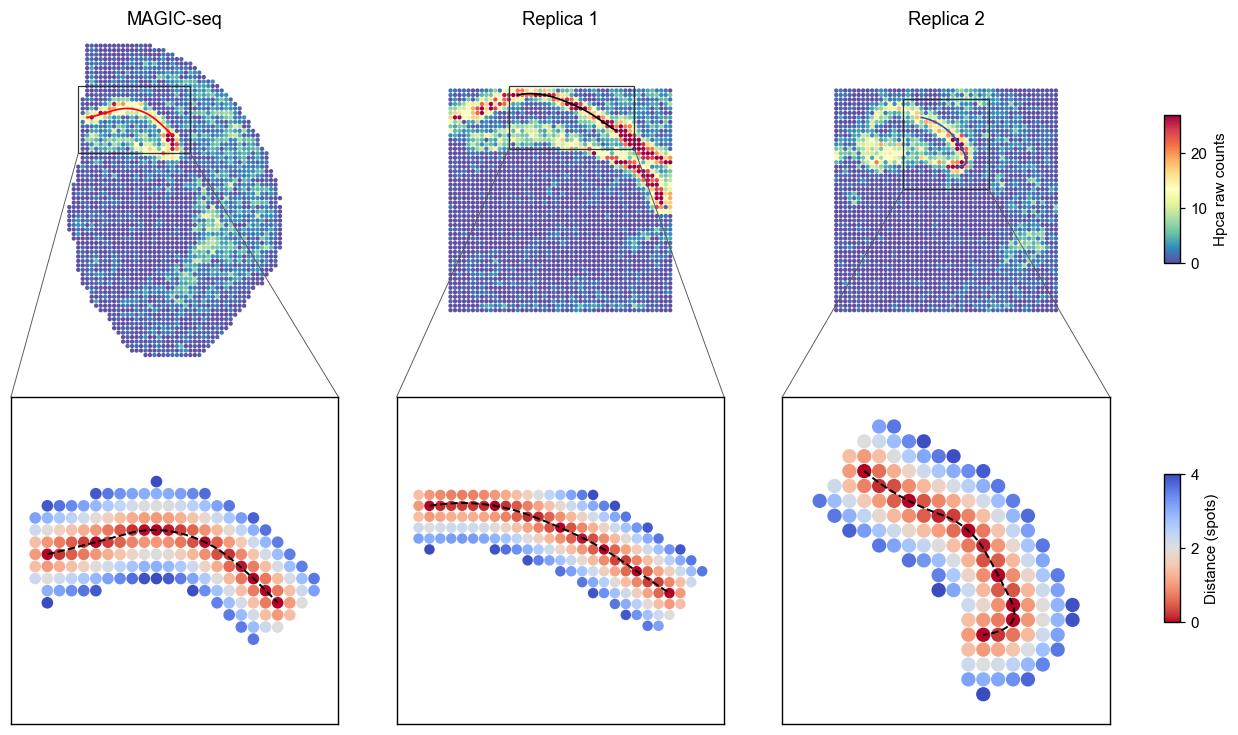

In [12]:
# 中文：绘制三个样本的Hpca空间表达、中心线及距离带放大图。
# English: Plot Hpca spatial expression, centerlines and enlarged distance bands for all three captures.
def plot_centerline_maps(spatial,display_lines,distance_lines):
    fig,axes=plt.subplots(2,3,figsize=(12,7.1))
    expression_norm=Normalize(*np.percentile(spatial.Hpca,[1,99]))
    max_span=max(np.ptp(d[['x','y']].to_numpy(),axis=0).max() for _,d in spatial.groupby('batch'))+4
    for col,(batch,label) in enumerate(BATCH_LABELS.items()):
        data=spatial[spatial.batch==batch];xy=data[['x','y']].to_numpy()
        ax=axes[0,col]
        expr=PatchCollection([Circle(p,.48) for p in xy],cmap='Spectral_r',norm=expression_norm,linewidths=0)
        expr.set_array(data.Hpca.to_numpy());ax.add_collection(expr)
        line=display_lines[batch]
        ax.plot(line[:,0],line[:,1],color=['red','black','#2458B0'][col],lw=1.1)
        mid=(xy.min(0)+xy.max(0))/2
        ax.set_xlim(mid[0]-max_span/2,mid[0]+max_span/2);ax.set_ylim(mid[1]+max_span/2,mid[1]-max_span/2)
        ax.set_aspect('equal');ax.axis('off');ax.set_title(label,fontsize=12,pad=8)
        chosen=data[data.signed_distance_spots.notna()];band_xy=chosen[['x','y']].to_numpy()
        lo=band_xy.min(0)-1;hi=band_xy.max(0)+1
        ax.add_patch(Rectangle(lo,*(hi-lo),fill=False,lw=.8,edgecolor='#333333'))
        zoom=axes[1,col]
        band=PatchCollection([Circle(p,.48) for p in band_xy],cmap='coolwarm_r',norm=Normalize(0,4),linewidths=0)
        band.set_array(np.abs(chosen.signed_distance_spots));zoom.add_collection(band)
        line=distance_lines[batch]
        zoom.plot(line[:,0],line[:,1],ls='--',color='black',lw=1.3)
        mid=(lo+hi)/2;half=max(hi-lo)/2+1
        zoom.set_xlim(mid[0]-half,mid[0]+half);zoom.set_ylim(mid[1]+half,mid[1]-half)
        zoom.set_aspect('equal');zoom.set_xticks([]);zoom.set_yticks([])
        for start,end in [([lo[0],hi[1]],(0,1)),(hi,(1,1))]:
            fig.add_artist(ConnectionPatch(start,end,coordsA='data',coordsB='axes fraction',axesA=ax,axesB=zoom,color='#555555',lw=.6))
    fig.subplots_adjust(left=.025,right=.88,bottom=.06,top=.94,wspace=.08,hspace=.10)
    c1=fig.add_axes([.91,.65,.012,.19]);cb1=fig.colorbar(expr,cax=c1);cb1.set_label('Hpca raw counts',fontsize=10)
    c2=fig.add_axes([.91,.19,.012,.19]);cb2=fig.colorbar(band,cax=c2,ticks=[0,2,4]);cb2.set_label('Distance (spots)',fontsize=10)
    finish(fig,'Figure3j_spatial_centerlines',axes.ravel())

if RUN_PROFILES:plot_centerline_maps(spatial,display_lines,distance_lines)


### Figure 3k — Mean expression across the centerline

Points represent mean raw counts in 0.5-spot bins, with empty bins filled by zero. Lines use Gaussian smoothing (sigma = 1 bin), quadratic interpolation and a 100-µm spot pitch. Both Replica captures are plotted separately in the same color; they are not pooled into one curve.

中文：三个基因分别展示分箱均值及平滑曲线；两个Replica样本各画一条曲线。保留原分箱、平滑、插值和100 µm距离换算参数，距离以100 µm的spot间距换算。

In [13]:
# 中文：按原参数计算分箱均值与平滑表达曲线。
# English: Calculate binned means and smoothed expression profiles with the original parameters.
def calculate_profiles(spatial,genes,max_distance=4,bin_size=.5,sigma=1,spot_pitch=100):
    bins=np.arange(-max_distance,max_distance+bin_size,bin_size)
    centers=bins[:-1]+bin_size/2
    points=[];curves=[]
    for batch in BATCH_LABELS:
        data=spatial[(spatial.batch==batch)&spatial.signed_distance_spots.notna()].copy()
        data['distance_bin']=pd.cut(data.signed_distance_spots,bins=bins,labels=centers)
        for gene in genes:
            y=data.groupby('distance_bin',observed=False)[gene].mean().fillna(0).to_numpy()
            x=centers*spot_pitch;assert np.all(np.diff(x)>0)
            xd=np.linspace(x.min(),x.max(),1000)
            yd=np.clip(make_interp_spline(x,gaussian_filter1d(y,sigma=sigma),k=2)(xd),0,None)
            points.append(pd.DataFrame({'batch':batch,'gene':gene,'distance_um':x,'mean_expression':y}))
            curves.append(pd.DataFrame({'batch':batch,'gene':gene,'distance_um':xd,'mean_expression':yd}))
    return pd.concat(points,ignore_index=True),pd.concat(curves,ignore_index=True)

if RUN_PROFILES:profile_points,profile_curves=calculate_profiles(spatial,GENES)


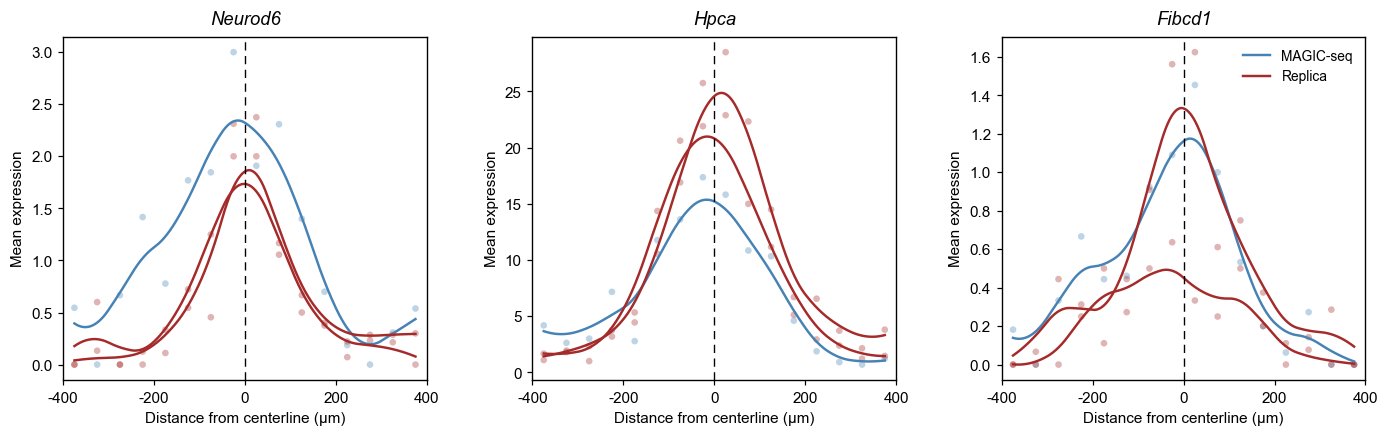

In [14]:
# 中文：并排绘制Neurod6、Hpca和Fibcd1的三样本表达曲线。
# English: Plot Neurod6, Hpca and Fibcd1 profiles for the three captures side by side.
def plot_expression_profiles(points,curves):
    fig,axes=plt.subplots(1,3,figsize=(12.8,4.4))
    for ax,gene in zip(axes,GENES):
        for batch in BATCH_LABELS:
            color='steelblue' if batch=='1' else 'brown'
            p=points[(points.gene==gene)&(points.batch==batch)]
            c=curves[(curves.gene==gene)&(curves.batch==batch)]
            ax.scatter(p.distance_um,p.mean_expression,s=19,color=color,alpha=.35,edgecolors='none')
            ax.plot(c.distance_um,c.mean_expression,color=color,lw=1.6)
        ax.axvline(0,color='black',ls=(0,(6,4)),lw=.9)
        ax.set_title(gene,fontstyle='italic',fontsize=12,pad=8)
        ax.set_xlabel('Distance from centerline (µm)',fontsize=10)
        ax.set_ylabel('Mean expression',fontsize=10)
        ax.set_xticks([-400,-200,0,200,400]);ax.set_xlim(-400,400)
    axes[-1].legend([Line2D([],[],color='steelblue',lw=1.6),Line2D([],[],color='brown',lw=1.6)],
                    ['MAGIC-seq','Replica'],loc='upper right',fontsize=9)
    fig.subplots_adjust(left=.065,right=.99,bottom=.18,top=.89,wspace=.29)
    finish(fig,'Figure3k_expression_profiles',axes)

if RUN_PROFILES:plot_expression_profiles(profile_points,profile_curves)


## Figure 3m–n — Gene-level reproducibility

Panel m compares Replica 1 (x) with Tissue (y); panel n compares Replica 2 (x) with Replica 1 (y). Each pair is independently joined by gene ID, then transformed as `log2(total_counts + 1)`. Pearson correlation uses all joined genes. Color indicates Gaussian kernel density with bandwidth 0.5 in the transformed coordinate system.

中文：两张相关图分别对齐各自共有基因，使用基因总计数的log2(count+1)，不进行CPM或均值归一化。R值由输入数据计算；默认保留代码而不出图。

In [15]:
# 中文：从各样本的var表提取原Gene_id和total_counts字段。
# English: Extract the original Gene_id and total_counts fields from each sample var table.
def load_gene_totals(path):
    import scanpy as sc
    obj=sc.read_h5ad(path,backed='r')
    try:
        missing={'Gene_id','total_counts'}-set(obj.var.columns)
        if missing:raise KeyError(f'Missing var fields: {sorted(missing)}')
        result=pd.DataFrame({'gene_id':obj.var.Gene_id.astype(str).to_numpy(),
                             'total_counts':pd.to_numeric(obj.var.total_counts).to_numpy()})
    finally:
        obj.file.close()
    if result.gene_id.duplicated().any():raise ValueError('Gene IDs must be unique before pairwise alignment.')
    assert np.isfinite(result.total_counts).all() and (result.total_counts>=0).all()
    return result

def align_gene_totals(x_table,y_table):
    pair=x_table.merge(y_table,on='gene_id',suffixes=('_x','_y'),validate='one_to_one')
    if len(pair)<3:raise ValueError('At least three common genes are required.')
    pair['x']=np.log2(pair.total_counts_x+1)
    pair['y']=np.log2(pair.total_counts_y+1)
    if pair.x.nunique()<2 or pair.y.nunique()<2:raise ValueError('Correlation requires variable expression in both inputs.')
    return pair


In [16]:
# 中文：按原高斯KDE和Pearson相关方法分别绘制m、n。
# English: Plot panels m and n using the original Gaussian KDE and Pearson correlation.
def plot_correlation(pair,x_label,y_label,stem):
    from sklearn.neighbors import KernelDensity
    xy=pair[['x','y']].to_numpy()
    density=np.exp(KernelDensity(kernel='gaussian',bandwidth=.5).fit(xy).score_samples(xy))
    r,pvalue=pearsonr(pair.x,pair.y)
    fig,ax=plt.subplots(figsize=(6.2,5.5))
    scatter=ax.scatter(pair.x,pair.y,c=density,cmap='viridis',s=12,edgecolors='none',rasterized=True)
    ax.text(.03,.96,f'R = {r:.3f}',transform=ax.transAxes,ha='left',va='top',fontsize=11)
    ax.set_xlabel(x_label,fontsize=12);ax.set_ylabel(y_label,fontsize=12)
    fig.colorbar(scatter,ax=ax,label='Density')
    fig.subplots_adjust(left=.14,right=.90,bottom=.14,top=.96)
    finish(fig,stem)
    return {'n_genes':len(pair),'pearson_r':float(r),'pearson_p':float(pvalue)}

if RUN_CORRELATIONS:
    totals={name:load_gene_totals(path) for name,path in CORRELATION_INPUTS.items()}
    m=align_gene_totals(totals['Replica1'],totals['Tissue'])
    n=align_gene_totals(totals['Replica2'],totals['Replica1'])
    result_m=plot_correlation(m,'Replica 1','Tissue','Figure3m_Tissue_vs_Replica1')
    result_n=plot_correlation(n,'Replica 2','Replica 1','Figure3n_Replica1_vs_Replica2')


## Data and software

The accompanying source index records the adapted notebook cells, and the input index records checksums for the measured profile data and original analysis notebooks. Software versions below describe the executed profile workflow; cell2location training and h/m/n plotting are optional sections.

中文：来源表记录代码单元和输入文件校验值；下方软件版本对应已执行的j/k部分。h、m/n不会随默认运行启动，cell2location训练也不会自动运行。

In [17]:
# 中文：展示代码来源和已执行部分的软件版本。
# English: Display code provenance and software versions for the executed workflow.
from importlib.metadata import version
display(read_table('panel_sources.csv'))
packages=['numpy','pandas','scipy','matplotlib']
display(pd.DataFrame({'Package':packages,'Version':[version(p) for p in packages]}))


,panel,source_notebook,source_cells_1_based,workflow
0,3h - anatomical map,get_adata.ipynb,"60-61, 67",Preserve the original 13-cluster annotation an...
1,3h - cell types,c2loc_mouse_brain.ipynb,"4-20, 23-36, 57, 63-64","Reference fitting, spatial posterior and propo..."
2,3j,LWMH.ipynb,7-8,Three-capture control points; cubic display an...
3,3k,LWMH.ipynb,10-11,"Half-spot bins, Gaussian smoothing and quadrat..."
4,3m-n,get_adata.ipynb,38-39,"Gene-ID intersection, log2(total counts + 1), ..."


,Package,Version
0,numpy,2.2.6
1,pandas,2.3.3
2,scipy,1.15.3
3,matplotlib,3.10.8
